In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/cs-training.csv", index_col=0)
print(df.shape)
df.head()

(150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [38]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


In [39]:
print(df.isnull().sum())
print()
print(df['SeriousDlqin2yrs'].value_counts())
print(df['SeriousDlqin2yrs'].value_counts(normalize=True) * 100)

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64
SeriousDlqin2yrs
0    93.316
1     6.684
Name: proportion, dtype: float64


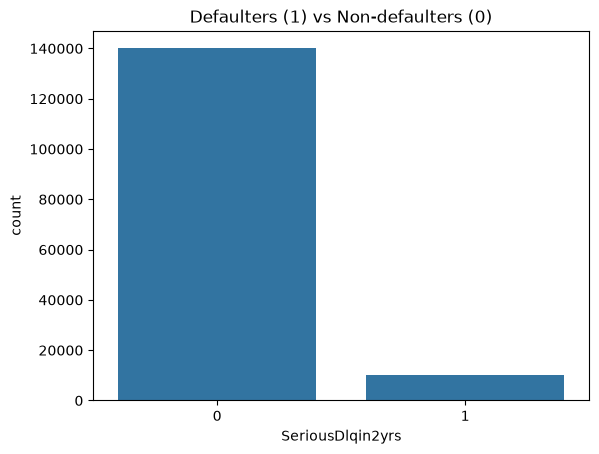

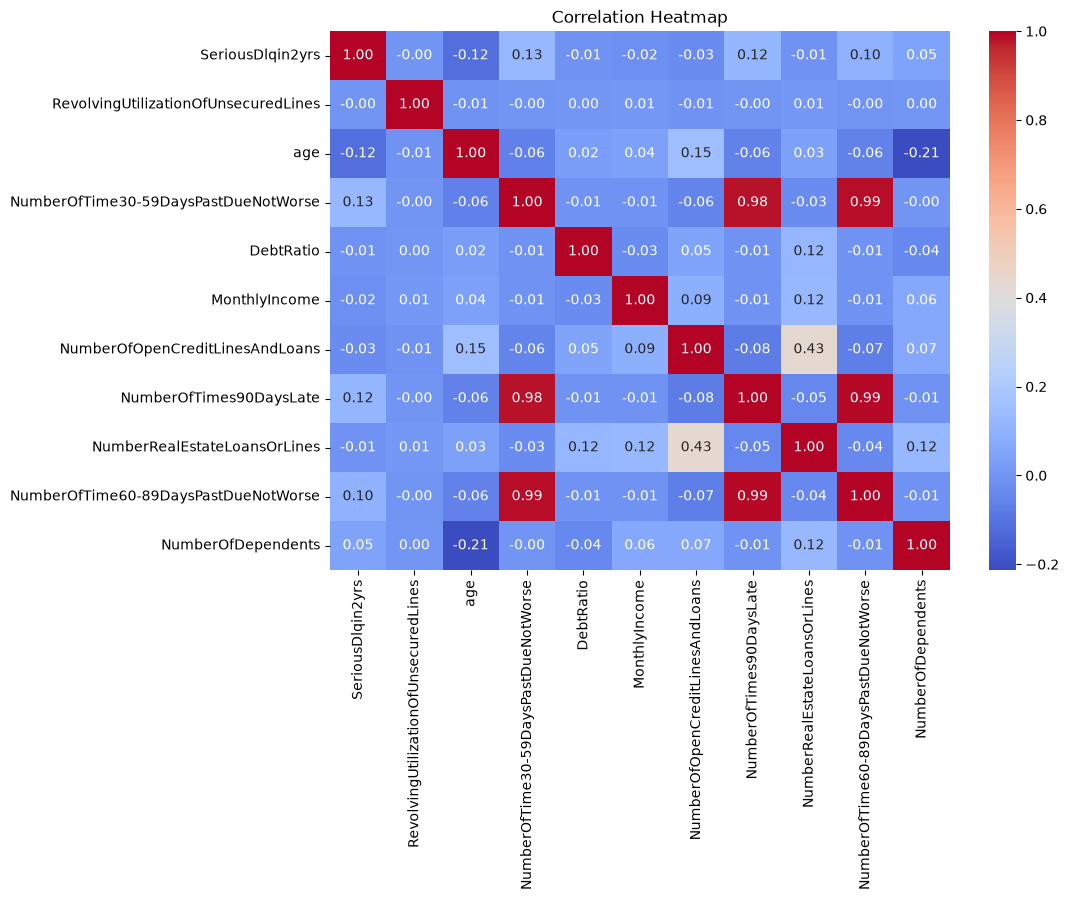

In [40]:
# Class balance
sns.countplot(x='SeriousDlqin2yrs', data=df)
plt.title("Defaulters (1) vs Non-defaulters (0)")
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [41]:
# Remove duplicates
df = df.drop_duplicates()

# Fill missing values with the median
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())
df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())

# Remove impossible ages
df = df[df['age'] >= 18]

# The late-payment columns use 96 and 98 as error codes, so remove those rows
late_cols = ['NumberOfTime30-59DaysPastDueNotWorse',
             'NumberOfTime60-89DaysPastDueNotWorse',
             'NumberOfTimes90DaysLate']
for col in late_cols:
    df = df[df[col] < 90]

# Cap extreme values at the 99th percentile
for col in ['RevolvingUtilizationOfUnsecuredLines', 'DebtRatio', 'MonthlyIncome']:
    df[col] = df[col].clip(upper=df[col].quantile(0.99))

print(df.shape)
print(df.isnull().sum().sum(), "missing values left")

(149165, 11)
0 missing values left


In [42]:
# Total number of late payments
df['total_late'] = (df['NumberOfTime30-59DaysPastDueNotWorse']
                    + df['NumberOfTime60-89DaysPastDueNotWorse']
                    + df['NumberOfTimes90DaysLate'])

# Has the person ever paid late? (1 = yes, 0 = no)
df['ever_late'] = (df['total_late'] > 0).astype(int)

# Monthly debt amount
df['monthly_debt'] = df['DebtRatio'] * df['MonthlyIncome']

# Income per family member
df['income_per_person'] = df['MonthlyIncome'] / (df['NumberOfDependents'] + 1)

# Log of income (reduces skew)
df['log_income'] = np.log1p(df['MonthlyIncome'])

# Credit lines per year of age
df['credit_lines_per_age'] = df['NumberOfOpenCreditLinesAndLoans'] / df['age']

print(df.shape)
df.head()

(149165, 17)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,total_late,ever_late,monthly_debt,income_per_person,log_income,credit_lines_per_age
1,1,0.766127,45,2,0.802982,9120.00,13,0,6,0,2.0,2,1,7323.197016,3040.00,9.118335,0.288889
2,0,0.957151,40,0,0.121876,2600.00,4,0,0,0,1.0,0,0,316.878123,1300.00,7.863651,0.100000
3,0,0.658180,38,1,0.085113,3042.00,2,1,0,0,0.0,2,1,258.914887,3042.00,8.020599,0.052632
4,0,0.233810,30,0,0.036050,3300.00,5,0,0,0,0.0,0,0,118.963951,3300.00,8.101981,0.166667
5,0,0.907239,49,1,0.024926,23095.52,7,0,1,0,0.0,1,1,575.671887,23095.52,10.047437,0.142857


In [43]:
new_cols = ['total_late', 'ever_late', 'monthly_debt', 'income_per_person',
            'log_income', 'credit_lines_per_age']
print(df[new_cols + ['SeriousDlqin2yrs']].corr()['SeriousDlqin2yrs'].sort_values())

income_per_person      -0.061341
log_income             -0.016675
monthly_debt           -0.015785
credit_lines_per_age    0.018192
ever_late               0.310683
total_late              0.392633
SeriousDlqin2yrs        1.000000
Name: SeriousDlqin2yrs, dtype: float64


In [44]:
from sklearn.model_selection import train_test_split

X = df.drop('SeriousDlqin2yrs', axis=1)
y = df['SeriousDlqin2yrs']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(119332, 16) (29833, 16)
0.06618509704019039 0.06620185700398887


In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
dt = DecisionTreeClassifier(class_weight='balanced', max_depth=6, random_state=42)
rf = RandomForestClassifier(class_weight='balanced', n_estimators=100,
                            max_depth=10, n_jobs=-1, random_state=42)

lr.fit(X_train_scaled, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)
print("Training done")

Training done


In [49]:
from sklearn.metrics import (classification_report, roc_auc_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve)

models = {
    "Logistic Regression": (lr, X_test_scaled),
    "Decision Tree":       (dt, X_test),
    "Random Forest":       (rf, X_test),
}

results = []
for name, (model, Xt) in models.items():
    pred = model.predict(Xt)
    proba = model.predict_proba(Xt)[:, 1]
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })
    print("=====", name, "=====")
    print(classification_report(y_test, pred))

results_df = pd.DataFrame(results).round(3)
results_df

===== Logistic Regression =====
              precision    recall  f1-score   support

           0       0.98      0.80      0.88     27858
           1       0.21      0.74      0.33      1975

    accuracy                           0.80     29833
   macro avg       0.59      0.77      0.61     29833
weighted avg       0.93      0.80      0.85     29833

===== Decision Tree =====
              precision    recall  f1-score   support

           0       0.98      0.79      0.88     27858
           1       0.20      0.75      0.32      1975

    accuracy                           0.79     29833
   macro avg       0.59      0.77      0.60     29833
weighted avg       0.93      0.79      0.84     29833

===== Random Forest =====
              precision    recall  f1-score   support

           0       0.98      0.83      0.90     27858
           1       0.23      0.73      0.35      1975

    accuracy                           0.82     29833
   macro avg       0.60      0.78      0.62 

,Model,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.211,0.739,0.328,0.850
1,Decision Tree,0.203,0.749,0.320,0.841
2,Random Forest,0.230,0.727,0.349,0.853


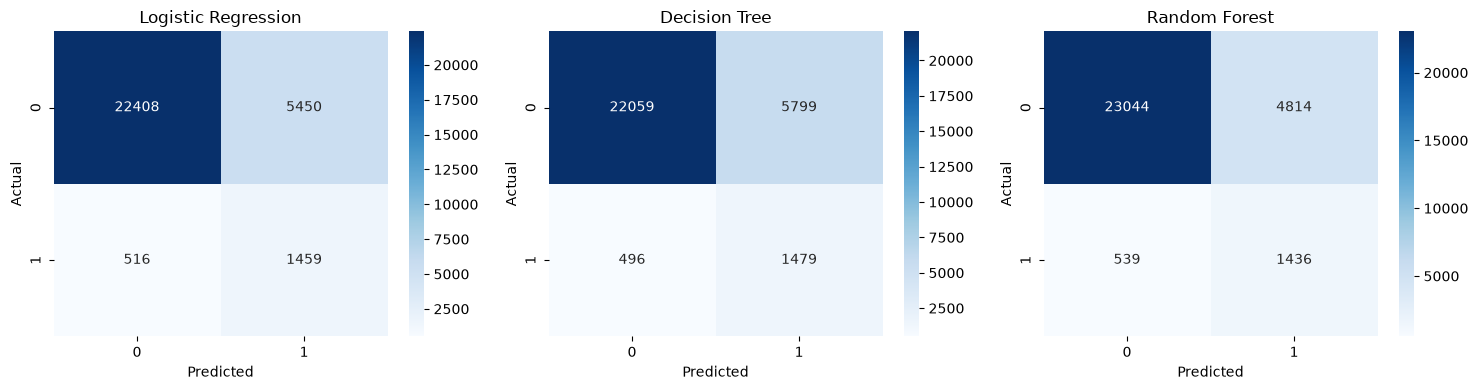

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (model, Xt)) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(Xt))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

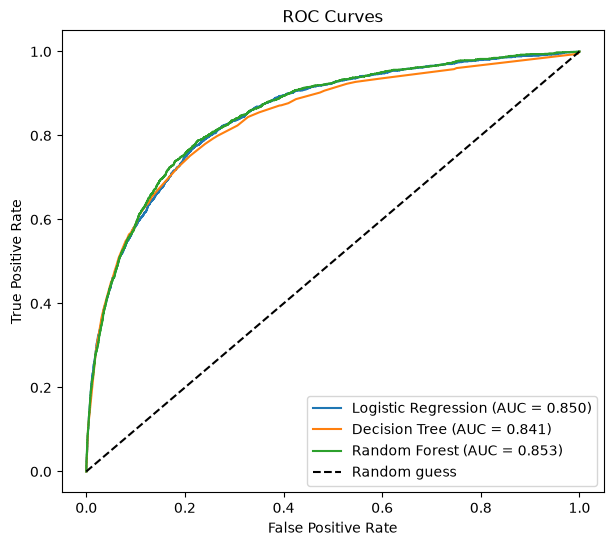

In [51]:
plt.figure(figsize=(7, 6))
for name, (model, Xt) in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(Xt)[:, 1])
    auc = roc_auc_score(y_test, model.predict_proba(Xt)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.savefig("roc_curves.png", dpi=150)
plt.show()

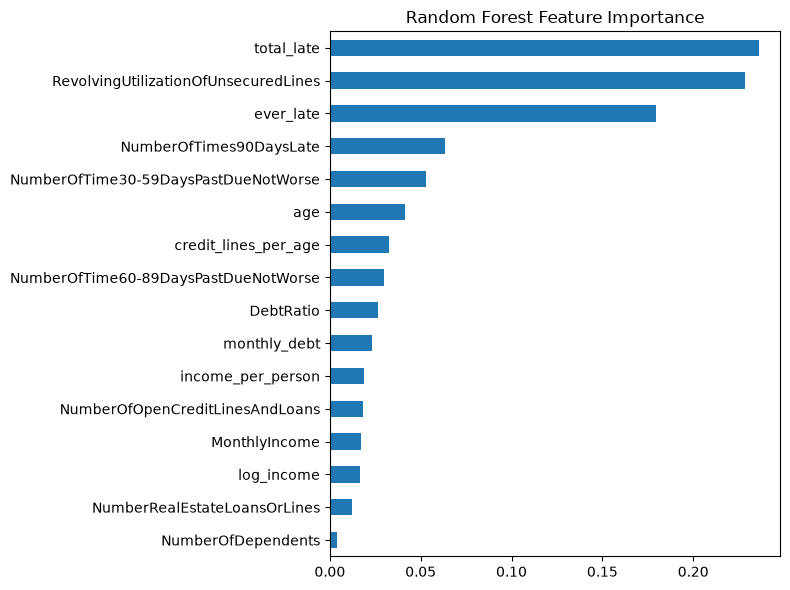

In [52]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", figsize=(8, 6))
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

In [53]:
print(results_df.to_string())
print()
print(pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(5))

                 Model  Precision  Recall     F1  ROC-AUC
0  Logistic Regression      0.211   0.739  0.328    0.850
1        Decision Tree      0.203   0.749  0.320    0.841
2        Random Forest      0.230   0.727  0.349    0.853

total_late                              0.235972
RevolvingUtilizationOfUnsecuredLines    0.228374
ever_late                               0.179484
NumberOfTimes90DaysLate                 0.063337
NumberOfTime30-59DaysPastDueNotWorse    0.052749
dtype: float64
